# Exploratory Data Analysis

**Purpose:** Explore booking trends, service demand, staff performance, revenue, and retention.


## 1. Load and Validate

In [83]:
# Import necessary libraries
import sys
sys.path.append("..")
 
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from src.validate import validate

sns.set_theme(style="whitegrid")   
FIG = Path(".../reports/figures"); 
FIG.mkdir(parents=True, exist_ok=True)

In [84]:
# Load and revalidate data
df = pd.read_parquet("../data/processed/booking_clean.parquet")
df = validate(df)

All checks passed: 49,462 rows, 20 columns


In [85]:
# Overview
print("Rows:", f"{len(df)}", "Columns:", f"{df.shape[1]}")
print("Date range:", df["start"].min().date(), "to", df["start"].max().date())
print("Unique customers:", df["id"].nunique())
print("Number of appointments:", df["number"].nunique()) 
print()
print(df["status"].value_counts(normalize=True).round(3))
print(df["source"].value_counts(normalize=True).round(3))
print(df["service_type"].value_counts(normalize=True).round(3))

Rows: 49462 Columns: 20
Date range: 2024-08-09 to 2026-10-31
Unique customers: 5219
Number of appointments: 38926

status
Completed    0.900
Cancel       0.092
No-show      0.007
Name: proportion, dtype: float64
source
2025.csv    0.439
2026.csv    0.426
2024.csv    0.135
Name: proportion, dtype: float64
service_type
Natural Nails        0.439
Nails Enhancement    0.437
Add-ons              0.049
Bare Necessities     0.039
Waxing Services      0.025
Kids Services        0.012
Name: proportion, dtype: float64


## 2. Booking Growth and Trends Analysis

### a) Number of bookings by year , by month, day in a week and hour in a day

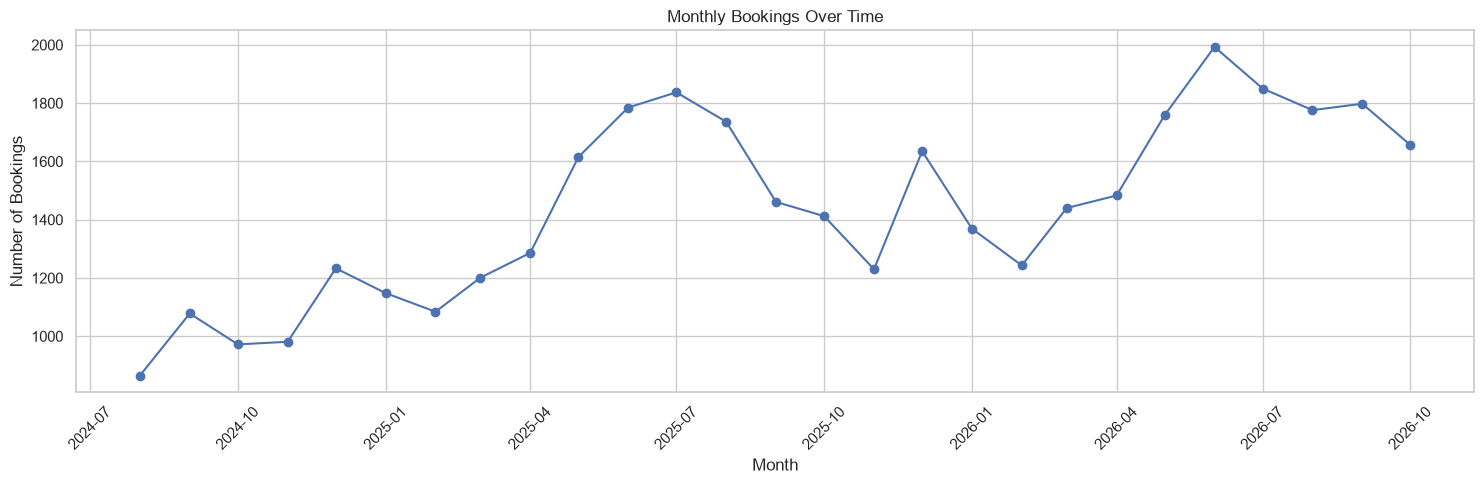

In [88]:
booking_time = (
    df.groupby(pd.Grouper(key="date_parsed", freq="MS"))["number"]
    .nunique())
plt.figure(figsize=(15, 5))

plt.plot(booking_time.index, booking_time.values, marker="o")

plt.title("Monthly Bookings Over Time")
plt.xlabel("Month")
plt.ylabel("Number of Bookings")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

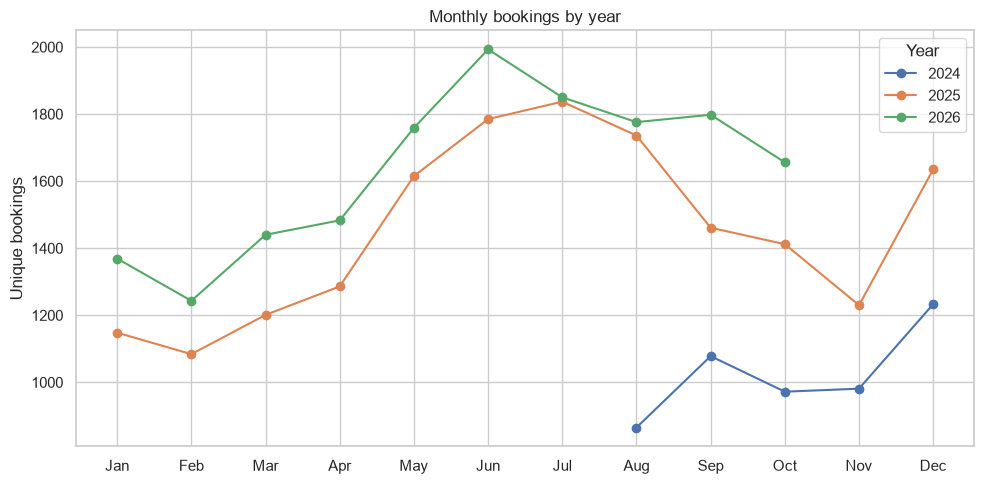

In [89]:
booking_year = (booking_time
           .to_frame("bookings")
           .assign(year=lambda d: d.index.year, month=lambda d: d.index.month)
           .pivot(index="month", columns="year", values="bookings"))

ax = booking_year.plot(figsize=(10, 5), marker="o")
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set(title="Monthly bookings by year", xlabel="", ylabel="Unique bookings")
ax.legend(title="Year")
plt.tight_layout()
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

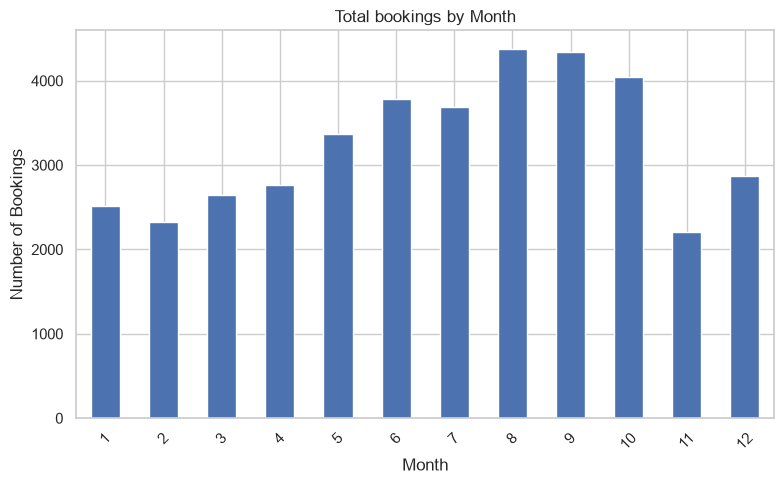

In [ ]:
booking_month= df.groupby("month")["number"].nunique()

booking_month.plot(kind="bar", figsize=(8,5))
plt.title("Total bookings by Month")
plt.xlabel("Month")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show


<function matplotlib.pyplot.show(close=None, block=None)>

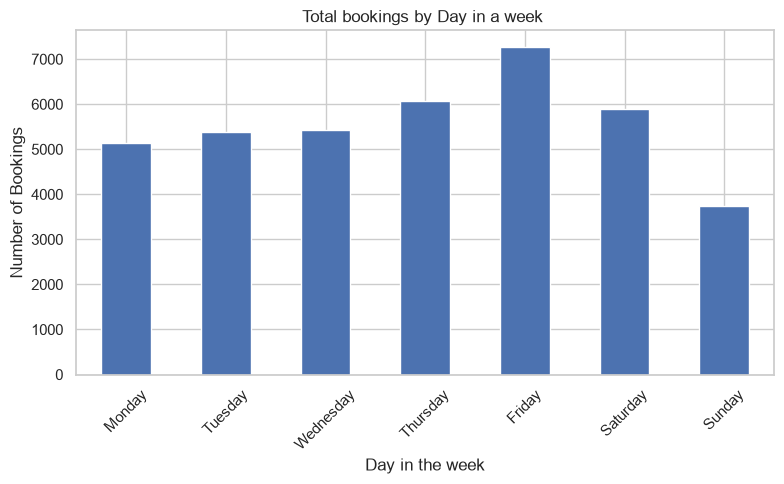

In [43]:
day_order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
booking_day = df.groupby("day_of_week")["number"].nunique()
booking_day = booking_day.reindex(day_order)
booking_day.plot(kind="bar", figsize = (8,5))
plt.title("Total bookings by Day in a week ")
plt.xlabel("Day in the week")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show

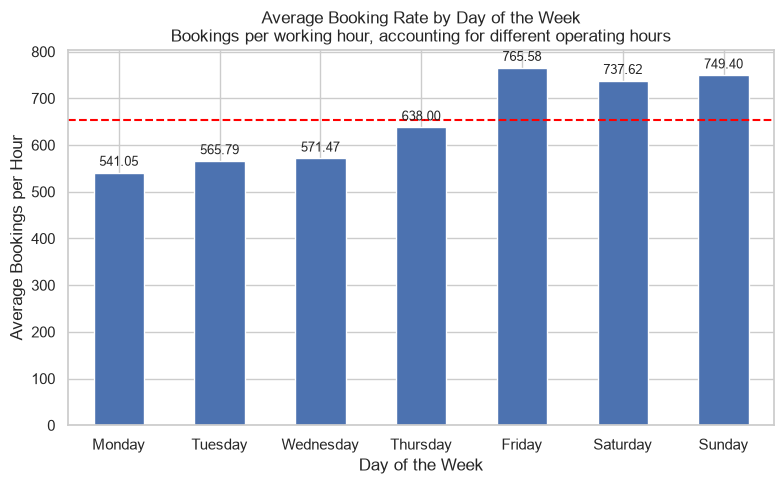

In [62]:
daily_hours = {
    "Monday": 9.5, "Tuesday": 9.5, "Wednesday": 9.5, "Thursday": 9.5, "Friday": 9.5, "Saturday": 8, "Sunday": 5
}
daily_rate = booking_day/booking_day.index.get_level_values("day_of_week").map(daily_hours)
avg_day_rate = daily_rate.groupby("day_of_week").mean()
avg_day_rate = avg_day_rate.reindex(day_order)
ax = avg_day_rate.plot(kind="bar", figsize=(8, 5))

ax.bar_label(ax.containers[0], fmt="%.2f", padding=3, fontsize = 9)
ax.set_title(
    "Average Booking Rate by Day of the Week\n"
    "Bookings per working hour, accounting for different operating hours",
    fontsize=12
)
ax.set_xlabel("Day of the Week")
ax.set_ylabel("Average Bookings per Hour")
ax.axhline(
    y=avg_day_rate.mean(),
    color="red",
    linestyle='--',
    linewidth=1.5,
    label='Weekly Average'
)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



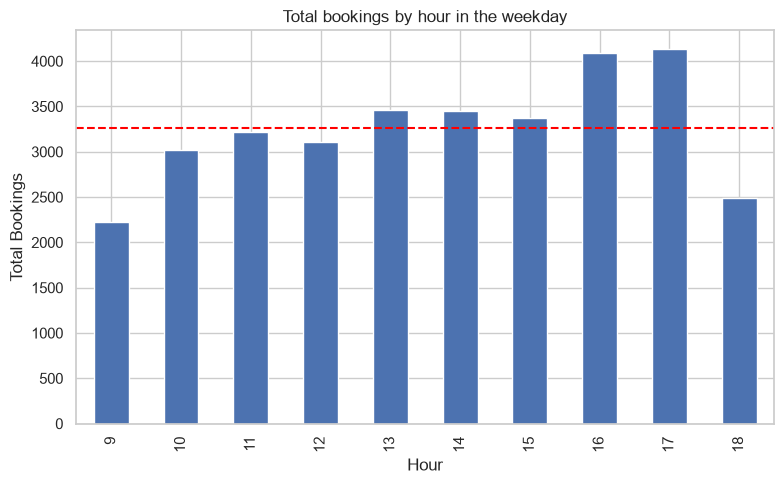

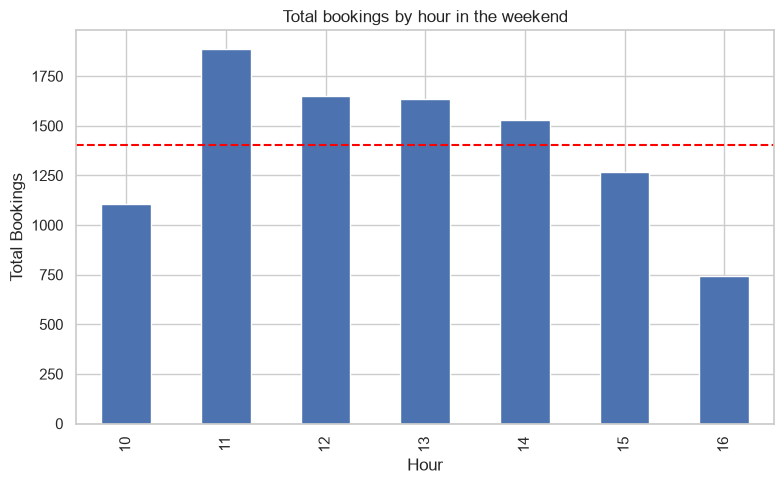

In [93]:
# Bookings per hour
booking_hour_weekday = df[(df["is_weekend"] == False) & (df["hour"]>=9) & (df["hour"]<=18)].groupby("hour")["number"].nunique()
ax = booking_hour_weekday.plot(kind="bar", figsize = (8,5))
ax.set_title("Total bookings by hour in the weekday")
ax.set_xlabel("Hour")
ax.set_ylabel("Total Bookings")
ax.axhline(
    y = booking_hour_weekday.mean(),
    color='red',
    linestyle="--"
)
plt.tight_layout() 
plt.show()

booking_hour_weekend = df[(df["is_weekend"] == True) & (df["hour"]>=10) & (df["hour"]<=16)].groupby("hour")["number"].nunique()
ax = booking_hour_weekend.plot(kind="bar", figsize = (8,5))
ax.set_title("Total bookings by hour in the weekend")
ax.set_xlabel("Hour")
ax.set_ylabel("Total Bookings")
ax.axhline(
    y = booking_hour_weekend.mean(),
    color='red',
    linestyle="--"
)
plt.tight_layout() 
plt.show()


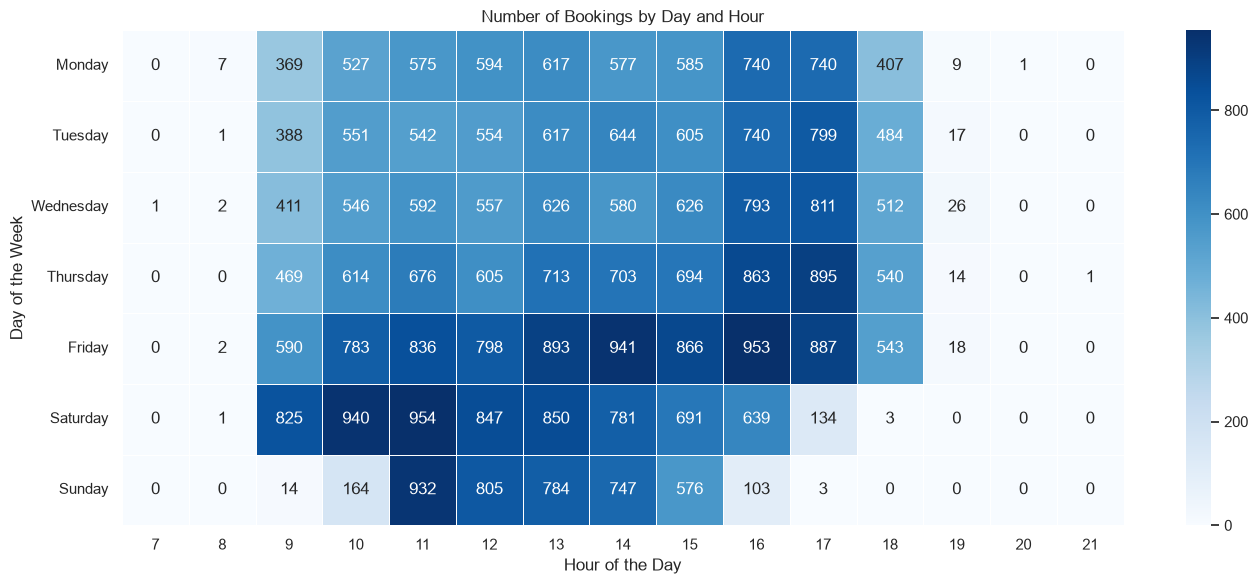

In [97]:
# Bookings through a week with specifc hour
booking_heatmap = df.groupby(["day_of_week","hour"])["number"].nunique().unstack(fill_value=0)
booking_heatmap = booking_heatmap.reindex(day_order)
plt.figure(figsize=(14, 6))

sns.heatmap(
    booking_heatmap,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.5
)

plt.title("Number of Bookings by Day and Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Day of the Week")
plt.tight_layout()
plt.show()

**Summary**:
- Overall, Pedi N Nails has experienced an increase in bookings over the three-year period, from Aug 2024 to Oct 2026. However, the business also shows clear seasonal patterns, with bookings peaking around June, slowing down afterward, and picking up again around December before decreasing until the summer.
- February and November are generally the slowest months, however the incomplete data for 2024 and 2026 should be considered when comparing yearly trends.
- Friday has the highest number of bookings, while Monday and Tuesday are generally the quietest days. Even after accounting for differences in operating hours, Friday, Saturday, and Sunday have the highest booking rates per hour, with Friday still leading.
- On weekdays, bookings are busiest between 4 PM and 5 PM. On weekends, demand peaks around 11 AM before gradually declining toward closing time.
- The heatmap makes these patterns easier to identify, particularly the high booking activity on Friday afternoons and weekend mornings, as well as the relatively low demand on Monday and Tuesday.
- These patterns may reflect customers' daily schedules, as people tend to book appointments when they have more free time, such as after work or during weekend mornings.
- Based on these informations, Pedi N Nails can prepare their business during peak seasons with better inventory and staff scheduling, while ensure stable bookings during low seasons by introducing promotions.


### b) Booking method: Traditional phone calls/messages vs. Online booking

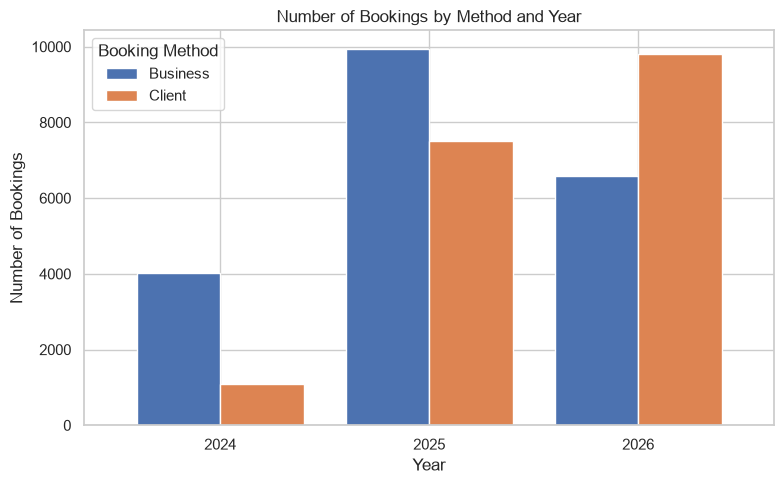

In [113]:
# Yearly comparison of two methods of booking
booking_method_year = df.groupby(["year","created_by"])["number"].nunique().unstack(fill_value=0)
ax = booking_method_year.plot(kind="bar",figsize=(8,5),width=0.8)
ax.set_title("Number of Bookings by Method and Year")
ax.set_xlabel("Year")
ax.set_ylabel("Number of Bookings")
ax.legend(title="Booking Method")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


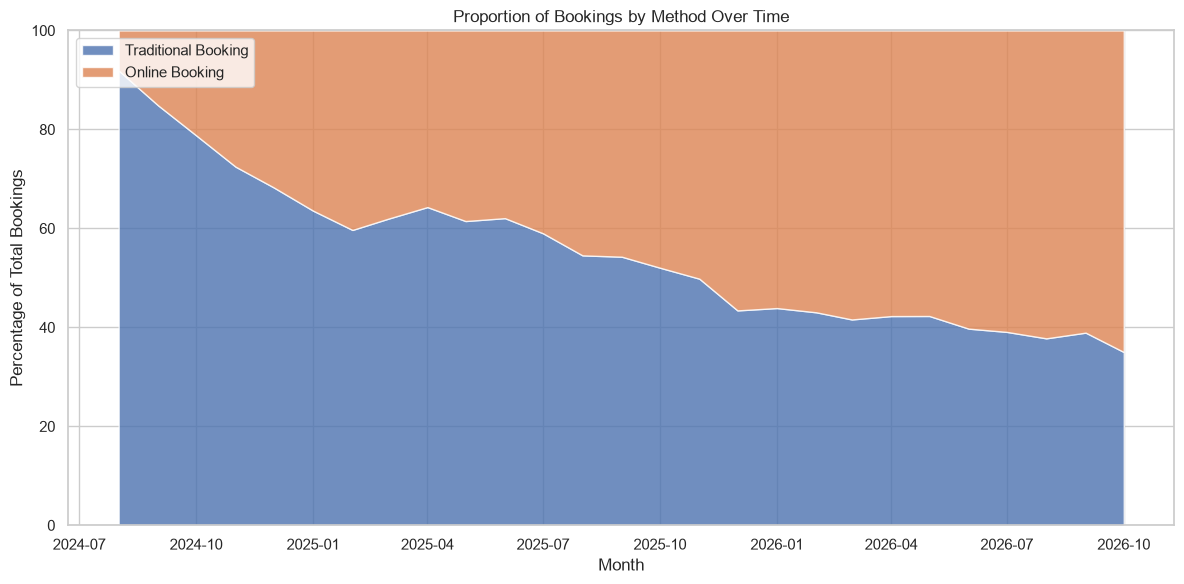

In [116]:
# Booking method proportion changes over the time
booking_method_over_time = df.groupby(["month","year","created_by"])["number"].nunique().unstack(fill_value=0)

booking_method_over_time.index = pd.to_datetime({
    "year": booking_method_over_time.index.get_level_values("year"),
    "month": booking_method_over_time.index.get_level_values("month"),
    "day": 1
})
booking_method_over_time = booking_method_over_time.sort_index()
booking_method_prop = booking_method_over_time.div(booking_method_over_time.sum(axis=1),axis=0)*100

plt.figure(figsize=(12, 6))

plt.stackplot(
    booking_method_prop.index,
    booking_method_prop["Business"],
    booking_method_prop["Client"],
    labels=["Traditional Booking", "Online Booking"],
    alpha=0.8
)

plt.title("Proportion of Bookings by Method Over Time")
plt.xlabel("Month")
plt.ylabel("Percentage of Total Bookings")
plt.ylim(0, 100)

plt.legend(loc="upper left")
plt.tight_layout()
plt.show()


**Summary:**
- In Q4 2024, online bookings accounted for only one-fourth the volume of traditional bookings. Throughout 2025, this gap steadily narrowed as online booking adoption accelerated. By 2026, online bookings surpassed traditional methods, outperforming them by approximately 33% (roughly 9,800 vs. 6,600 bookings)
- Online booking has proven to be a strong strategic move, surging from under 10% at launch to over 60% of total bookings as customers increasingly prefer digital convenience.
- With more customers preferring online booking, adding promotions and reminders directly to the booking website can help reach and retain a wider audience.


## 3. Service Demand and Revenue Analysis

### a) Specific service and Service type popularity

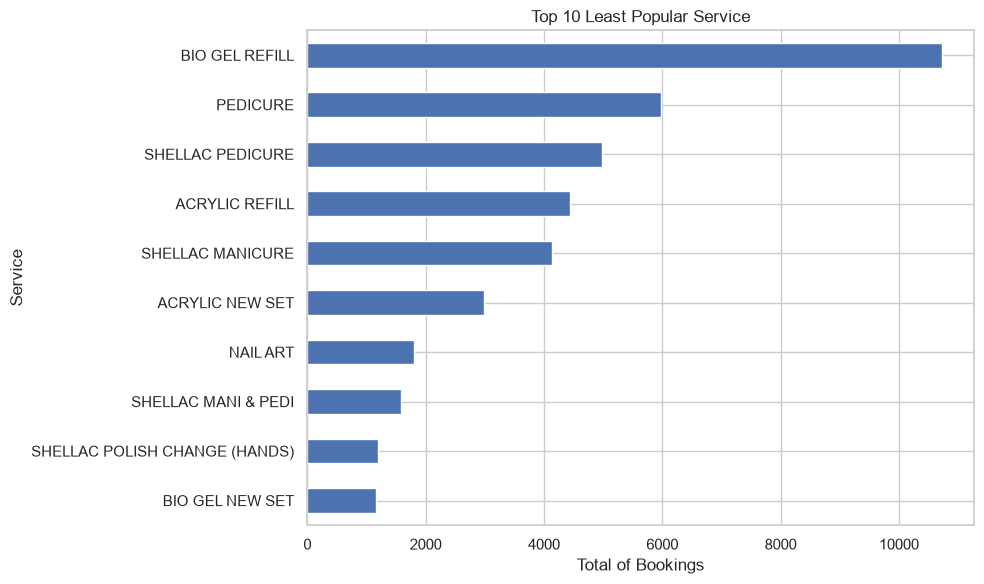

In [ ]:
top_10_popular_services = df.groupby("service_name")["number"].nunique().sort_values(ascending=False).head(10)

top_10_popular_services.plot(kind="barh", figsize=(10, 6))
plt.title("Top 10 Most Popular Service")
plt.xlabel("Total of Bookings")
plt.ylabel("Service")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

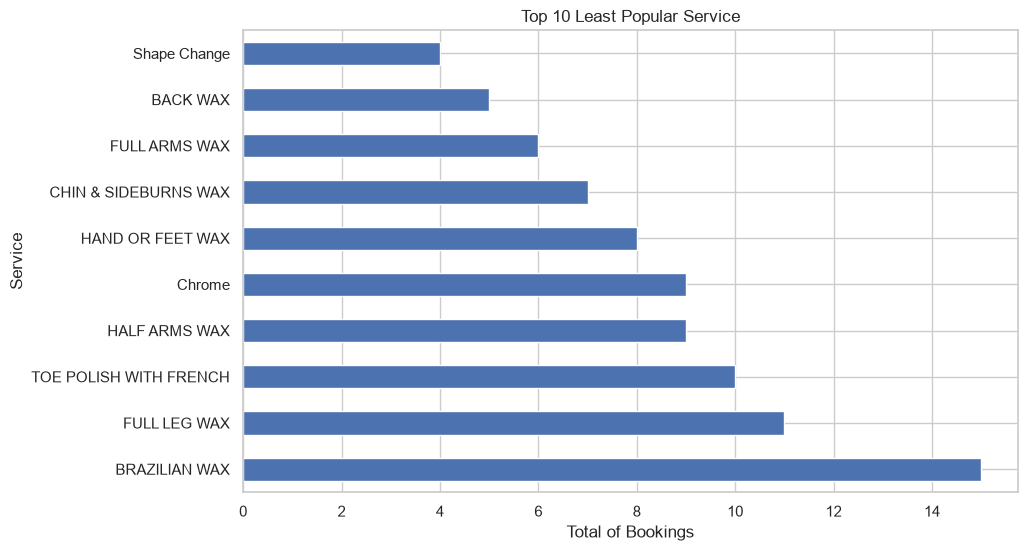

In [136]:
top_10_least_popular_services = df.groupby("service_name")["number"].nunique().sort_values(ascending=True).head(10)

top_10_least_popular_services.plot(kind="barh", figsize=(10, 6))
plt.title("Top 10 Least Popular Service")
plt.xlabel("Total of Bookings")
plt.ylabel("Service")
plt.gca().invert_yaxis()
plt.show()

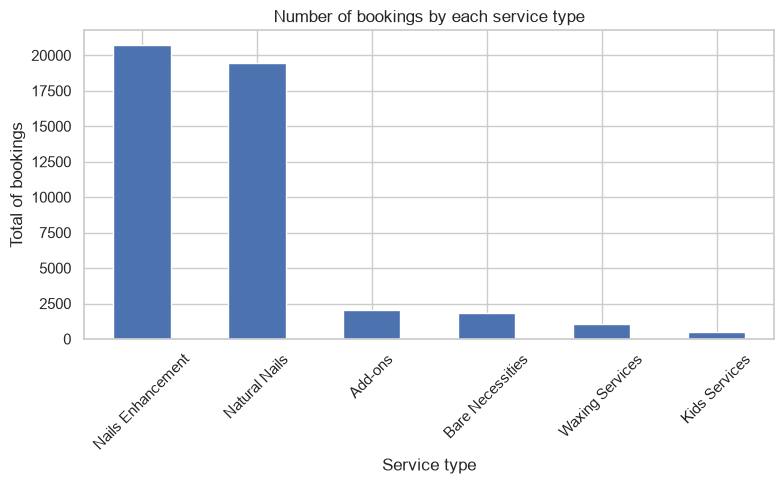

In [142]:
# The most popular type of service
service_type_popularity = df.groupby(["service_type"])["number"].nunique().sort_values(ascending=False)
service_type_popularity.plot(kind="bar",figsize=(8,5))

plt.title("Number of bookings by each service type")
plt.xlabel("Service type")
plt.ylabel("Total of bookings")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Summary**:
- Nail enhancement and natural nail services are the two most popular service categories in the business, ranking first and second respectively.
- Within nail enhancement services, Bio Gel and Acrylic are the most popular options. Customers also appear to prefer refills on existing sets over getting a new set.
- For natural nail services, pedicures are among the best-performing services, ranking second in booking volume, closely followed by manicures.
- Waxing is the least popular service category, with eight waxing services recording the lowest booking numbers.

### b) Revenue per Service Analysis

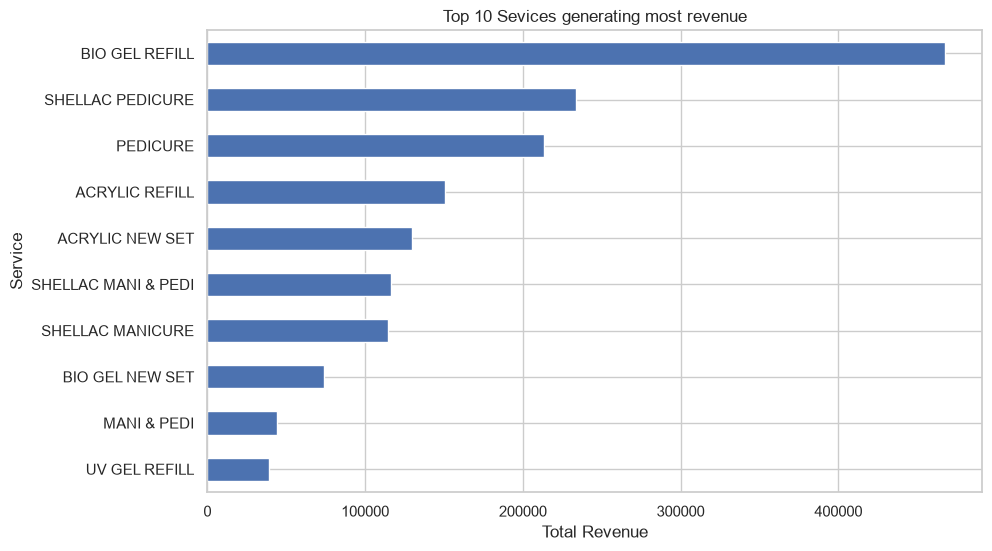

In [146]:
# Top 10 services generating most revenue
top_10_revenue = df.groupby(["service_name"])["service_price"].sum().sort_values(ascending=False).head(10)
top_10_revenue.plot(kind="barh", figsize=(10,6))
plt.title("Top 10 Sevices generating most revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Service")
plt.gca().invert_yaxis()
plt.show()

<Axes: xlabel='service_name'>

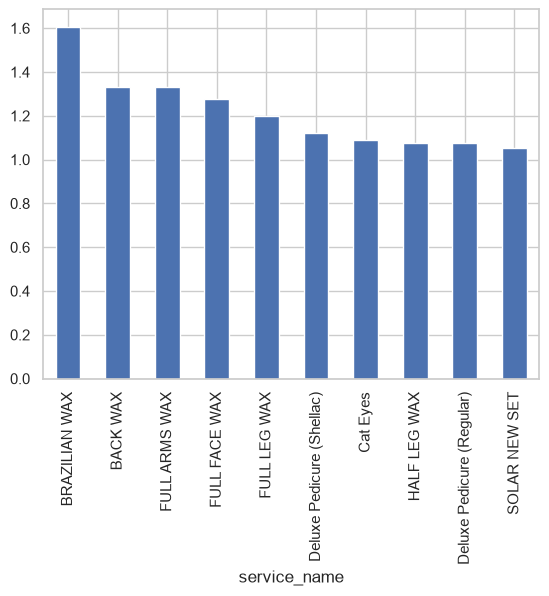

In [151]:
revenue_per_minute = df.groupby(["service_name"]).apply(lambda x: x["service_price"].sum() / x["duration"].sum()).sort_values(ascending=False).head(10)
revenue_per_minute.plot(kind="bar")